# 4. The P-FFA search pipeline: from time series to candidates

Notebooks 1–3 call the P-FFA on one fixed grid. A real search covers a
wide band, and that changes two things:

- **planning**: a fixed number of phase bins cannot serve every period.
  `FFAFreqSweep` splits the band into octaves, doubles the number of
  bins (and the grid tolerance `eta`) each octave down so the time
  resolution of the profile stays the same, and cuts each octave into
  chunks that fit the memory limit;
- **candidates**: a bright pulsar passes the S/N threshold at hundreds
  of neighbouring trials, and also at its harmonics. The sweep groups
  the passing trials into clusters, keeps one representative per
  cluster, and can flag clusters that are harmonics of a brighter one.

The result is one HDF5 file with the candidate table, which
`loki.candidates` reads and exports for folding with PulsarX. The `loki`
command-line program runs the same pipeline (`loki search ffa -c
config.toml`). See `docs/candidates.md` for the file schema.

Runtime: about 10 seconds; memory: about 1 GB.

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
from matplotlib import pyplot as plt

from loki import libloki
from loki.candidates import CandidateFile, export_pulsarx
from pyloki.simulation.pulse import PulseSignalConfig

libloki.set_log_level("warning")  # hide loki's per-chunk info messages
SEED = 1
NTHREADS = 4  # CPU threads; raise it on a machine of your own
OUTDIR = Path("_output/04_ffa_pipeline")
OUTDIR.mkdir(parents=True, exist_ok=True)

## Simulated data

One 7 ms pulsar with acceleration 200 m/s² and a folded S/N of 12, in
2^22 samples of 64 µs (about 4.5 minutes).

In [2]:
accel = 200.0
cfg = PulseSignalConfig(
    period=0.007,
    dt=64e-6,
    nsamps=2**22,
    snr=12,
    ducy=0.1,
    mod_kwargs={"acc": accel},
    seed=SEED,
)
tim_data = cfg.generate(shape="gaussian")
print(f"T_obs = {cfg.tobs:.1f} s, true frequency = {cfg.freq:.6f} Hz")

T_obs = 268.4 s, true frequency = 142.857143 Hz


## Configuration

The search covers 25–200 Hz and ±250 m/s². `max_process_memory_gb`
caps the memory of the whole sweep; the planner sizes the chunks from it.
`snr_min` is the S/N a trial needs to enter the candidate stage.

`CandidateOptions` controls the grouping; the defaults cluster
neighbouring detections. Here harmonic flagging is also switched on.
`ObservationMetadata` carries what the search itself does not know (DM,
start MJD, timing frame); it is copied into the output and used for the
PulsarX export. When loki reads a `.tim` or `.dat` file, these come from
the file header.

In [3]:
search_cfg = libloki.configs.PulsarSearchConfig(
    nsamps=cfg.nsamps,
    tsamp=cfg.dt,
    nbins=64,
    eta=1,
    param_limits=np.array([[-250.0, 250.0], [25.0, 200.0]]),
    ducy_max=0.2,
    wtsp=1.5,
    use_fourier=True,
    nthreads=NTHREADS,
    max_process_memory_gb=2.0,
    snr_min=6.5,
)

candidate_options = libloki.configs.CandidateOptions()
candidate_options.flag_harmonics = True

observation = libloki.io.ObservationMetadata()
observation.source = "simulated"
observation.dm = 0.0
observation.start_mjd = 60000.0
observation.barycentric = False

## Run the sweep

In [4]:
sweep = libloki.ffa.FFAFreqSweep(
    search_cfg,
    show_progress=False,
    candidates=candidate_options,
)
sweep.execute(tim_data.ts_e, tim_data.ts_v, str(OUTDIR), "sim", observation=observation)
result_file = OUTDIR / "sim_ffa_results.h5"
print(f"wrote {result_file}")

wrote _output/04_ffa_pipeline/sim_ffa_results.h5


## The plan

The file records every chunk the planner made (`/search/regions`). Each
octave down doubles `nbins`; inside an octave, chunks get narrower
towards high frequency, where the grid is denser.

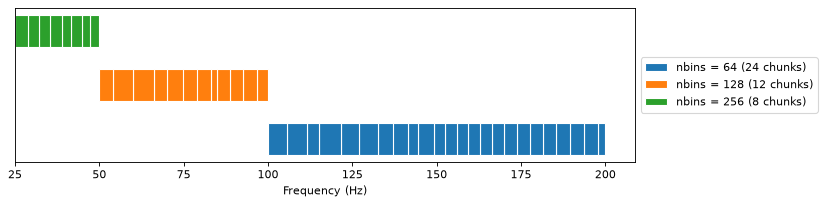

44 chunks, search time 6.5 s


In [5]:
import h5py

with h5py.File(result_file, "r") as handle:
    regions = [dict(g.attrs) for g in handle["search/regions"].values()]
    runtime = float(handle["search"].attrs["total_runtime"])

fig, ax = plt.subplots(figsize=(10, 2.5), dpi=80)
for nbins in sorted({int(r["nbins"]) for r in regions}):
    chunks = [r for r in regions if int(r["nbins"]) == nbins]
    ax.barh(
        [np.log2(nbins)] * len(chunks),
        [r["f_max"] - r["f_min"] for r in chunks],
        left=[r["f_min"] for r in chunks],
        height=0.6,
        edgecolor="white",
        label=f"nbins = {nbins} ({len(chunks)} chunks)",
    )
ax.set_xlabel("Frequency (Hz)")
ax.set_yticks([])
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()
print(f"{len(regions)} chunks, search time {runtime:.1f} s")

## Candidates

`CandidateFile` reads the candidate table: one row per cluster, with the
native search parameters (`param_sets`: acceleration, frequency), the
equivalent spin frequency derivatives (`f0`, `f1`), the S/N, the number
of detections in the cluster, and the harmonic relation, if any.

In [6]:
with CandidateFile(result_file) as candidates:
    print(f"{len(candidates)} candidates; observation: {candidates.metadata['source']}")
    cands = next(candidates.iter_batches())
with CandidateFile(result_file, table="detections") as detections:
    n_detections = len(detections)
    dets = next(detections.iter_batches(batch_size=n_detections))

print(f"from {n_detections} detections above S/N {search_cfg.snr_min}\n")
print(f"{'S/N':>6} {'accel':>8} {'freq (Hz)':>12} {'members':>8}  harmonic of")
for i in range(len(cands["snr"])):
    num, den = cands["harmonic_numerator"][i], cands["harmonic_denominator"][i]
    parent = cands["parent_cluster_id"][i]
    relation = f"{num}/{den} x cluster {parent}" if den else "-"
    a, f = cands["param_sets"][i]
    print(
        f"{cands['snr'][i]:6.2f} {a:8.1f} {f:12.6f} "
        f"{cands['member_count'][i]:8d}  {relation}",
    )

5 candidates; observation: simulated
from 632 detections above S/N 6.5

   S/N    accel    freq (Hz)  members  harmonic of
 11.11    196.4   142.857029      588  -
  8.08    201.4    71.428412       37  1/2 x cluster 0
  7.02    210.5    35.714296        5  1/4 x cluster 0
  6.58    246.4   142.858659        1  -
  6.55    200.0    47.618987        1  1/3 x cluster 0


The first candidate is the pulsar, built from several hundred
detections. The next ones are its subharmonics (1/2, 1/4 and 1/3 of the
spin frequency, where the fold shows 2, 4 or 3 pulses), and are flagged
as such (`remove_harmonics` would drop them). One more candidate, a single
detection, lies at the edge of the pulsar's acceleration-frequency track,
just outside its cluster.

The plot shows all detections (dots) and the selected candidates
(circles) in the searched plane.

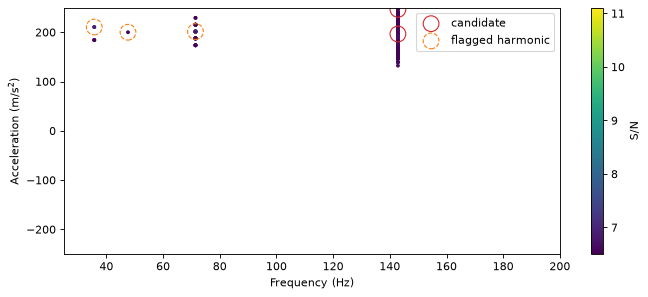

In [7]:
a_det, f_det = dets["param_sets"][:, 0], dets["param_sets"][:, 1]
a_can, f_can = cands["param_sets"][:, 0], cands["param_sets"][:, 1]
harmonic = cands["harmonic_denominator"] > 0

fig, ax = plt.subplots(figsize=(10, 4), dpi=80)
sc = ax.scatter(f_det, a_det, c=dets["snr"], s=6, cmap="viridis")
ax.scatter(
    f_can[~harmonic],
    a_can[~harmonic],
    s=200,
    facecolors="none",
    edgecolors="tab:red",
    label="candidate",
)
ax.scatter(
    f_can[harmonic],
    a_can[harmonic],
    s=200,
    facecolors="none",
    edgecolors="tab:orange",
    linestyles="--",
    label="flagged harmonic",
)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Acceleration (m/s$^2$)")
ax.set_xlim(*search_cfg.param_limits[1])
ax.set_ylim(*search_cfg.param_limits[0])
fig.colorbar(sc, label="S/N")
ax.legend()
plt.show()

## Export for folding

`export_pulsarx` writes the candidates as a PulsarX candidate file (the
command-line equivalent is `loki-candidates`). The parameters refer to
the middle of the observation; that epoch comes from the observation
metadata.

In [8]:
summary = export_pulsarx(result_file, OUTDIR / "sim.cands")
print(summary)
print((OUTDIR / "sim.cands").read_text())

{'count': 5, 'dm': 0.0, 'pepoch': 60000.00155344592, 'timing_frame': 'topocentric'}
#id DM accel F0 F1 F2 S/N
#timing_frame topocentric
#Pepoch 60000.001553445923 (pass explicitly with --pepoch)
64436260904 0 196.42857142857144 142.85702891084898 -9.3602094911567771e-05 0 11.108486175537109
133155759683 0 201.38888888888891 71.428411533677092 -4.7982822949687172e-05 0 8.0784111022949219
171804554173 0 210.5263157894737 35.714295706835557 -2.5080014174926001e-05 0 7.0215725898742676
64437577926 0 246.42857142857144 142.85865869941119 -0.00011742942238893068 0 6.5789027214050293
154624348841 0 200 47.618986827586383 -3.1767968510793146e-05 0 6.5507383346557617

